## SEB and IBPM analysis

In [1]:
import os
import glob

import math
import matplotlib as mpl
import matplotlib.colors as colors
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import cartopy as cart
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cartopy.mpl.ticker as cticker
from cartopy.util import add_cyclic_point
#import seaborn as sns

import numpy as np
import xarray as xr
import cftime
import pandas as pd

In [2]:
work = "locale_mc" # or "levante"

if work == "levante":
    data_path = "/home/m/m301093/data/clean/"
    out_path = "/home/m/m301093/results_biophys/"
if work == "locale_wnd":
    data_path = "G:/My Drive/MPIM/data/"
    out_path = "G:/My Drive/MPIM/Figures/"
if work == "locale_mc":
    data_path = "/Users/matteomastropierro/Documents/afforestation_LUMIP/data/"
    out_path = "/Users/matteomastropierro/Documents/afforestation_LUMIP/Submission/" \
    "Figures/"

## Functions

In [3]:
def xr_multimodel_sign(xr_in, models):
    # Computes the Multimodel MEAN and STD
    # xr_in: list of xarray models
    mm = xr.concat(xr_in, dim = "esm", coords = "minimal", compat = "override")
    
    std = xr.concat(xr_in, dim = "esm", coords = "minimal", compat = "override").std(dim = "esm")
    
    # Multimodel agreement in the sign of the sensitivity
    sign = xr.where(mm > 0, 1, -1)
    agreement = (np.abs(sign.sum(dim = "esm")/len(models)))
    
    mean = mm.mean(dim = "esm")
    return (mean, std, agreement)

In [4]:
def get_pixel_area(ds):
    """Calculate the area of each pixel in m^2 given latitudes and longitudes."""
    lat = ds.lat.values
    lon = ds.lon.values
    # Earth radius in meters
    R = 6.371e6
    rad = (2 * math.pi / 360)  # Convert degrees to radians

    # Reshape lat and lon to make sure they have the correct shape
    if lat[0] > lat[-1]:
        lat = lat[::-1]

    # Calculate the area of each pixel
    pixel_areas = np.zeros((len(lat) - 1, len(lon) - 1))
    for i in range(len(lat) - 1):
        for j in range(len(lon) - 1):
            pixel_areas[i, j] = (R ** 2 *
                                 (math.sin(rad * lat[i + 1]) - math.sin(rad * lat[i])) *
                                 abs(lon[j + 1] - lon[j]) * rad)

    pixel_areas = xr.DataArray(pixel_areas, coords=[lat[:-1], lon[:-1]], dims=["lat", "lon"])
    return pixel_areas

def cell_weight(ds):
    R = 6.371e6
    dϕ = np.deg2rad(ds.lat[1] - ds.lat[0])
    dλ = np.deg2rad(ds.lon[1] - ds.lon[0])
    dlat = R * dϕ * xr.ones_like(ds.lon)
    dlon = R * dλ * np.cos(np.deg2rad(ds.lat))
    cell_area = dlon * dlat
    return(cell_area)

def lon180(ds):
    ds.coords['lon'] = (ds.coords['lon'] + 180) % 360 - 180
    ds = ds.sortby(ds.lon)
    return ds

In [5]:
import xesmf as xe

def xr_regrid(data, method, lon_bnds, lat_bnds, xres, yres):
    # Regrid XARRAY using xESMF library (https://xesmf.readthedocs.io/en/stable/index.html)
    # data: input data
    # method: "bilinear", "conservative", "conservative_normed", "patch", "nearest_s2d", "nearest_d2s"
    
    lonmin = lon_bnds[0]; lonmax = lon_bnds[1]
    latmin = lat_bnds[0]; latmax = lat_bnds[1]
    xr_out = xe.util.cf_grid_2d(lonmin, lonmax, xres, latmin, latmax, yres)
   
    regrid = xe.Regridder(data, xr_out, method)

    data_regrid = regrid(data, keep_attrs=True)

    return data_regrid
def xr_multimodel_sign(xr_in, models):
    # Computes the Multimodel MEAN and STD
    # xr_in: list of xarray models
    mm = xr.concat(xr_in, dim = "esm", coords = "minimal", compat = "override")
    
    std = xr.concat(xr_in, dim = "esm", coords = "minimal", compat = "override").std(dim = "esm")
    
    # Multimodel agreement in the sign of the sensitivity
    sign = xr.where(mm > 0, 1, -1)
    agreement = (np.abs(sign.sum(dim = "esm")/len(models)))
    
    mean = mm.mean(dim = "esm")
    return (mean, std, agreement)

In [6]:
#### --------- Mann-Whitney Test --------- ####
from scipy.stats import mannwhitneyu

# Test applied on a grid-cell basis. For every gid-cell, the statistical difference between two time series is computed.
# 1st time series: Nino years' (DS_models_hist_nino)
# 2nd time series: Reference climatology (DS_models_hist_clim or DS_models_hist_clim_neutral)  

## -- Function for grid-cell operations -- ##
def multi_apply_along_axis(func1d, axis, arrs, *args, **kwargs):
    """
    Given a function `func1d(A, B, C, ..., *args, **kwargs)`  that acts on 
    multiple one dimensional arrays, apply that function to the N-dimensional
    arrays listed by `arrs` along axis `axis`
    
    If `arrs` are one dimensional this is equivalent to::
    
        func1d(*arrs, *args, **kwargs)
    
    If there is only one array in `arrs` this is equivalent to::
    
        numpy.apply_along_axis(func1d, axis, arrs[0], *args, **kwargs)
        
    All arrays in `arrs` must have compatible dimensions to be able to run
    `numpy.concatenate(arrs, axis)`
    
    Arguments:
        func1d:   Function that operates on `len(arrs)` 1 dimensional arrays,
                  with signature `f(*arrs, *args, **kwargs)`
        axis:     Axis of all `arrs` to apply the function along
        arrs:     Iterable of numpy arrays
        *args:    Passed to func1d after array arguments
        **kwargs: Passed to func1d as keyword arguments
    """
    # Concatenate the input arrays along the calculation axis to make one big
    # array that can be passed in to `apply_along_axis`
    carrs = np.concatenate(arrs, axis)
    
    # We'll need to split the concatenated arrays up before we apply `func1d`,
    # here's the offsets to split them back into the originals
    offsets=[]
    start=0
    for i in range(len(arrs)-1):
        start += arrs[i].shape[axis]
        offsets.append(start)
            
    # The helper closure splits up the concatenated array back into the components of `arrs`
    # and then runs `func1d` on them
    def helperfunc(a, *args, **kwargs):
        arrs = np.split(a, offsets)
        return func1d(*[*arrs, *args], **kwargs)
    
    # Run `apply_along_axis` along the concatenated array
    return np.apply_along_axis(helperfunc, axis, carrs, *args, **kwargs)


def xr_multipletest(p, alpha=0.05, method='fdr_bh', **multipletests_kwargs):
    """Apply statsmodels.stats.multitest.multipletests for multi-dimensional xr.objects."""
    from statsmodels.stats.multitest import multipletests
    # stack all to 1d array
    p_stacked = p.stack(s=p.dims)
    # mask only where not nan: https://github.com/statsmodels/statsmodels/issues/2899
    mask = np.isfinite(p_stacked)
    pvals_corrected = np.full(p_stacked.shape, np.nan)
    reject = np.full(p_stacked.shape, np.nan)
    # apply test where mask
    reject[mask] = multipletests(
        p_stacked[mask], alpha=alpha, method=method, **multipletests_kwargs)[0]
    pvals_corrected[mask] = multipletests(
        p_stacked[mask], alpha=alpha, method=method, **multipletests_kwargs)[1]

    def unstack(reject, p_stacked):
        """Exchange values from p_stacked with reject (1d array) and unstack."""
        xreject = p_stacked.copy()
        xreject.values = reject
        xreject = xreject.unstack()
        return xreject

    reject = unstack(reject, p_stacked)
    pvals_corrected = unstack(pvals_corrected, p_stacked)
    return reject, pvals_corrected


In [7]:
def lag_linregress_3D(x, y, lagx=0, lagy=0):
    """
    Input: Two xr.Datarrays of any dimensions with the first dim being time. 
    Thus the input data could be a 1D time series, or for example, have three dimensions (time,lat,lon). 
    Datasets can be provied in any order, but note that the regression slope and intercept will be calculated
    for y with respect to x.
    Output: Covariance, correlation, regression slope and intercept, p-value, and standard error on regression
    between the two datasets along their aligned time dimension.  
    Lag values can be assigned to either of the data, with lagx shifting x, and lagy shifting y, with the specified lag amount. 
    """ 
    #1. Ensure that the data are properly alinged to each other. 
    x,y = xr.align(x,y)
    
    #2. Add lag information if any, and shift the data accordingly
    if lagx!=0:
        #If x lags y by 1, x must be shifted 1 step backwards. 
        #But as the 'zero-th' value is nonexistant, xr assigns it as invalid (nan). Hence it needs to be dropped
        x   = x.shift(time = -lagx).dropna(dim='time')
        #Next important step is to re-align the two datasets so that y adjusts to the changed coordinates of x
        x,y = xr.align(x,y)

    if lagy!=0:
        y   = y.shift(time = -lagy).dropna(dim='time')
        x,y = xr.align(x,y)
 
    #3. Compute data length, mean and standard deviation along time axis for further use: 
    n     = x.shape[0]
    xmean = x.mean(axis=0)
    ymean = y.mean(axis=0)
    xstd  = x.std(axis=0)
    ystd  = y.std(axis=0)
    
    #4. Compute covariance along time axis
    cov   =  np.sum((x - xmean)*(y - ymean), axis=0)/(n)
    
    #5. Compute correlation along time axis
    cor   = cov/(xstd*ystd)
    
    #6. Compute regression slope and intercept:
    slope     = cov/(xstd**2)
    intercept = ymean - xmean*slope
    y_pred =  intercept + slope*x
    res = y - y_pred

    #7. Compute P-value and standard error
    #Compute t-statistics
    tstats = cor*np.sqrt(n-2)/np.sqrt(1-cor**2)
    stderr = slope/tstats
    
    from scipy.stats import t
    pval   = t.sf(tstats, n-2)*2
    pval   = xr.DataArray(pval, dims=cor.dims, coords=cor.coords)

    #return cov,cor,slope,intercept,pval,stderr
    results = {}
    results["cor"] = cor
    results["coef"] = slope
    results["pval"] = pval
    return results

## LUH2 dataset

Import the LUH2 dataset for the ssp126 and the ssp370 scenarios

In [8]:
luh2_ssp370 = xr.open_dataset(os.path.join(data_path + "added_tree_cover_input4MIPs_landState_ScenarioMIP_UofMD-AIM-ssp370-2-1-f_gn_2015-2100.nc"),
                                decode_times = False)

luh2_ssp126 = xr.open_dataset(os.path.join(data_path + "added_tree_cover_input4MIPs_landState_ScenarioMIP_UofMD-IMAGE-ssp126-2-1-f_gn_2015-2100.nc"),
                                decode_times = False)

In [9]:
luh2_ssp370_states = xr.open_dataset(os.path.join(data_path + "multiple-states_input4MIPs_landState_ScenarioMIP_UofMD-AIM-ssp370-2-1-f_gn_2015-2100.nc"),
                                decode_times = False)

luh2_ssp126_states = xr.open_dataset(os.path.join(data_path + "multiple-states_input4MIPs_landState_ScenarioMIP_UofMD-IMAGE-ssp126-2-1-f_gn_2015-2100.nc"),
                                decode_times = False)

/Users/matteomastropierro/miniconda/envs/geo_clim_py3.12/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/matteomastropierro/miniconda/envs/geo_clim_py3.12/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/matteomastropierro/miniconda/envs/geo_clim_py3.12/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/matteomastropierro/miniconda/envs/geo_clim_py3.12/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)


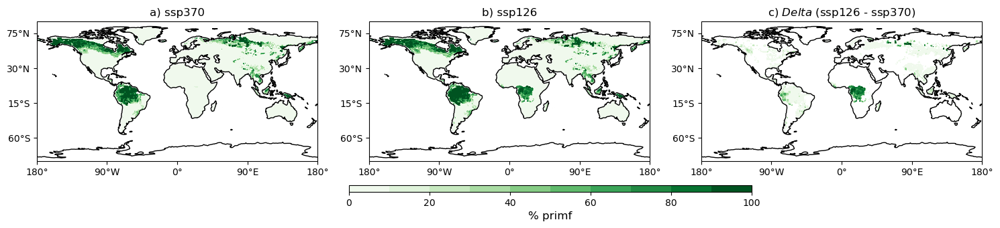

In [10]:
import matplotlib.patches as mpatches

width_inch = 15
height_inch = 5

fig, axs = plt.subplots(nrows=1, ncols=3, figsize=(width_inch, height_inch), subplot_kw={'projection': ccrs.PlateCarree()})
axs = axs.flatten()
clevs=np.arange(0,101,10)
cmap = "Greens"

#---
axs[0].set_title("a) ssp370")
data = luh2_ssp370_states.primf.isel(time = -1)*100
lats = data.lat
# Add the cyclic point
data,lons=add_cyclic_point(data,coord=data['lon'])
map = axs[0].contourf(lons, lats, data, clevs, transform = ccrs.PlateCarree(), cmap = cmap) #
axs[0].set_xticks(np.arange(-180,181,90), crs=ccrs.PlateCarree())
lon_formatter = cticker.LongitudeFormatter()
axs[0].xaxis.set_major_formatter(lon_formatter)
axs[0].set_yticks(np.arange(-60,91,45), crs=ccrs.PlateCarree())
lat_formatter = cticker.LatitudeFormatter()
axs[0].yaxis.set_major_formatter(lat_formatter)
axs[0].add_feature(cfeature.NaturalEarthFeature('physical', 'ocean', '50m', edgecolor='face', facecolor="white"))
axs[0].coastlines()

#--- 
axs[1].set_title("b) ssp126")
data = luh2_ssp126_states.primf.isel(time = -1)*100
lats = data.lat
# Add the cyclic point
data,lons=add_cyclic_point(data,coord=data['lon'])
map = axs[1].contourf(lons, lats, data, clevs, transform = ccrs.PlateCarree(), cmap = cmap) #
axs[1].set_xticks(np.arange(-180,181,90), crs=ccrs.PlateCarree())
lon_formatter = cticker.LongitudeFormatter()
axs[1].xaxis.set_major_formatter(lon_formatter)
axs[1].set_yticks(np.arange(-60,91,45), crs=ccrs.PlateCarree())
lat_formatter = cticker.LatitudeFormatter()
axs[1].yaxis.set_major_formatter(lat_formatter)
axs[1].add_feature(cfeature.NaturalEarthFeature('physical', 'ocean', '50m', edgecolor='face', facecolor="white"))
axs[1].coastlines()

#---
axs[2].set_title("c) ${Delta}$ (ssp126 - ssp370)")
data = luh2_ssp126_states.primf.isel(time = -1)*100 - luh2_ssp370_states.primf.isel(time = -1)*100
lats = data.lat
# Add the cyclic point
data,lons=add_cyclic_point(data,coord=data['lon'])
map = axs[2].contourf(lons, lats, data, clevs, transform = ccrs.PlateCarree(), cmap = cmap) #
axs[2].set_xticks(np.arange(-180,181,90), crs=ccrs.PlateCarree())
lon_formatter = cticker.LongitudeFormatter()
axs[2].xaxis.set_major_formatter(lon_formatter)
axs[2].set_yticks(np.arange(-60,91,45), crs=ccrs.PlateCarree())
lat_formatter = cticker.LatitudeFormatter()
axs[2].yaxis.set_major_formatter(lat_formatter)
axs[2].add_feature(cfeature.NaturalEarthFeature('physical', 'ocean', '50m', edgecolor='face', facecolor="white"))
axs[2].coastlines()

# #---
# data = (luh2_ssp126_states.primf.isel(time = -1)*100 - luh2_ssp126_states.primf.isel(time = 0)*100)
# lats = data.lat
# # Add the cyclic point
# data,lons=add_cyclic_point(data,coord=data['lon'])
# map = axs[3].contourf(lons, lats, data, clevs, transform = ccrs.PlateCarree(), cmap = cmap) #
# axs[3].set_xticks(np.arange(-180,181,90), crs=ccrs.PlateCarree())
# lon_formatter = cticker.LongitudeFormatter()
# axs[3].xaxis.set_major_formatter(lon_formatter)
# axs[3].set_yticks(np.arange(-60,91,45), crs=ccrs.PlateCarree())
# lat_formatter = cticker.LatitudeFormatter()
# axs[3].yaxis.set_major_formatter(lat_formatter)
# axs[3].add_feature(cfeature.NaturalEarthFeature('physical', 'ocean', '50m', edgecolor='face', facecolor="white"))
# axs[3].coastlines()
# axs[3].set_title("a) ssp126 $\Delta_{treefrac}$")

#---
fig.subplots_adjust(bottom=0.2, top=2, left=0.1, right=0.8, wspace=0.2, hspace=0.2)
fig.tight_layout()
cb_ax = fig.add_axes([0.35, 0.2, 0.4, 0.02])
cbar = plt.colorbar(map, cax=cb_ax, extend='both', orientation='horizontal', fraction=0.046, pad=0.04)  
cbar.ax.set_xlabel("% primf", fontsize=12)

title = "LUH2_ssp370_ssp126_delta_2100"
output_file = os.path.join(out_path, title) + ".png"
plt.savefig(output_file, bbox_inches='tight', dpi = 500)

plt.show()
plt.close()

## Import preprocessed data

In [11]:
models = [ "ACCESS-ESM1-5", "CMCC-ESM2", "CESM2", "CanESM5", "IPSL-CM6A-LR", "MPI-ESM1-2-LR", "UKESM1-0-LL"]

In [12]:
scenario = 'ssp126Lu'
xr_aff = []
for i,mm in enumerate(models):
    filepath = glob.glob(os.path.join(data_path + 'xr_' + scenario + "_" + mm + '.nc'))[0]                                       ## List of files sorted by name
    content = xr.open_dataset(filepath, drop_variables=["time_bnds","lon_bnds","lat_bnds"],engine = 'netcdf4',chunks={"time": 240})
    content = content.assign_attrs(esm = mm)
    xr_aff.append(content)


scenario = 'ssp370'
xr_ctl = []
for i,mm in enumerate(models):
    filepath = glob.glob(os.path.join(data_path + 'xr_' + scenario + "_" + mm + '.nc'))[0]                                       ## List of files sorted by name
    content = xr.open_dataset(filepath, drop_variables=["time_bnds","lon_bnds","lat_bnds"],engine = 'netcdf4',chunks={"time": 240})
    content = content.assign_attrs(esm = mm)
    xr_ctl.append(content)


/var/folders/h1/tgvjn96s32q5lfh32xvkh1hh0000gp/T/ipykernel_74942/444337245.py:5: UserWarning: The specified chunks separate the stored chunks along dimension "time" starting at index 240. This could degrade performance. Instead, consider rechunking after loading.
  content = xr.open_dataset(filepath, drop_variables=["time_bnds","lon_bnds","lat_bnds"],engine = 'netcdf4',chunks={"time": 240})
/var/folders/h1/tgvjn96s32q5lfh32xvkh1hh0000gp/T/ipykernel_74942/444337245.py:5: UserWarning: The specified chunks separate the stored chunks along dimension "time" starting at index 240. This could degrade performance. Instead, consider rechunking after loading.
  content = xr.open_dataset(filepath, drop_variables=["time_bnds","lon_bnds","lat_bnds"],engine = 'netcdf4',chunks={"time": 240})
/var/folders/h1/tgvjn96s32q5lfh32xvkh1hh0000gp/T/ipykernel_74942/444337245.py:5: UserWarning: The specified chunks separate the stored chunks along dimension "time" starting at index 240. This could degrade perfo

In [13]:
scenario = 'ssp126Lu'
xr_aff_pft = []
for i,mm in enumerate(models):
    filepath = glob.glob(os.path.join(data_path + 'xr_' + scenario + "_" + mm + '_pft.nc'))[0]                                       ## List of files sorted by name
    content = xr.open_dataset(filepath, drop_variables=["time_bnds","lon_bnds","lat_bnds"],engine = 'netcdf4',chunks={"time": 240})
    content = content.assign_attrs(esm = mm)
    xr_aff_pft.append(content)


scenario = 'ssp370'
xr_ctl_pft = []
for i,mm in enumerate(models):
    filepath = glob.glob(os.path.join(data_path + 'xr_' + scenario + "_" + mm + '_pft.nc'))[0]                                       ## List of files sorted by name
    content = xr.open_dataset(filepath, drop_variables=["time_bnds","lon_bnds","lat_bnds"],engine = 'netcdf4',chunks={"time": 240})
    content = content.assign_attrs(esm = mm)
    xr_ctl_pft.append(content)


/var/folders/h1/tgvjn96s32q5lfh32xvkh1hh0000gp/T/ipykernel_74942/3490561412.py:5: UserWarning: The specified chunks separate the stored chunks along dimension "time" starting at index 240. This could degrade performance. Instead, consider rechunking after loading.
  content = xr.open_dataset(filepath, drop_variables=["time_bnds","lon_bnds","lat_bnds"],engine = 'netcdf4',chunks={"time": 240})
/var/folders/h1/tgvjn96s32q5lfh32xvkh1hh0000gp/T/ipykernel_74942/3490561412.py:5: UserWarning: The specified chunks separate the stored chunks along dimension "time" starting at index 240. This could degrade performance. Instead, consider rechunking after loading.
  content = xr.open_dataset(filepath, drop_variables=["time_bnds","lon_bnds","lat_bnds"],engine = 'netcdf4',chunks={"time": 240})
/var/folders/h1/tgvjn96s32q5lfh32xvkh1hh0000gp/T/ipykernel_74942/3490561412.py:5: UserWarning: The specified chunks separate the stored chunks along dimension "time" starting at index 240. This could degrade pe

### Data homogenization

In [14]:
# CanESM5 does not provide Latent Heat
# We derive it as Rn - H (ignoring Ground Heat fluxes that are negligible over land)

xr_ctl[3]["hfls"] = (xr_ctl[3].rsds - xr_ctl[3].rlds) - xr_ctl[3].hfss
xr_aff[3]["hfls"] = (xr_aff[3].rsds - xr_aff[3].rlds) - xr_aff[3].hfss

# Rename ta to tas 
xr_aff[3] = xr_aff[3].rename({"ta":"tas"})
xr_ctl[3] = xr_ctl[3].rename({"ta":"tas"})

# Select the first pressure level
xr_aff[3] = xr_aff[3].isel(plev = 0)
xr_ctl[3] = xr_ctl[3].isel(plev = 0)

# Try to interpolate surface temperature for CanESM5
xr_ctl[3]["tas"] = (xr_ctl[3].ts + xr_ctl[3].tas)/2
xr_aff[3]["tas"] = (xr_aff[3].ts + xr_aff[3].tas)/2


In [15]:
# Convert pr and evspsbl from kg m-2 s-1 to mm month-1
for i,mm in enumerate(models):
    xr_ctl[i]["pr"] = xr_ctl[i].pr*86400* xr_ctl[i].time.dt.days_in_month
    xr_aff[i]["pr"] = xr_aff[i].pr*86400* xr_aff[i].time.dt.days_in_month
    
    xr_ctl[i]["pr"].attrs=dict(units="mm/months")
    xr_aff[i]["pr"].attrs=dict(units="mm/months")

    if mm == "CMCC-ESM2" or "CESM2": # LE in W*m^2; λ is in MJ kg-1 = MW*s kg-1 
        # https://earthscience.stackexchange.com/questions/20733/fluxnet15-how-to-convert-latent-heat-flux-to-actual-evapotranspiration
        xr_ctl[i]["evspsbl"] = xr_ctl[i].hfls/(2.501 - (2.361e-3) * (xr_ctl[i].tas-273.15))*10**6
        xr_aff[i]["evspsbl"] = xr_aff[i].hfls/(2.501 - (2.361e-3) * (xr_aff[i].tas-273.15))*10**6

    else:
        None
    
    xr_ctl[i]["evspsbl"] = xr_ctl[i].evspsbl*86400* xr_ctl[i].time.dt.days_in_month
    xr_aff[i]["evspsbl"] = xr_aff[i].evspsbl*86400* xr_aff[i].time.dt.days_in_month
    
    xr_ctl[i]["evspsbl"].attrs=dict(units="mm/months")
    xr_aff[i]["evspsbl"].attrs=dict(units="mm/months")
    
    xr_aff[i]["albedo"] = xr_aff[i].rsus / xr_aff[i].rsds
    xr_ctl[i]["albedo"] = xr_ctl[i].rsus / xr_ctl[i].rsds
    

In [16]:
# Homogenize lat and lon
for i,mm in enumerate(models):
    content = xr_aff[i]
    xr_aff_pft[i]["lat"] = content.tas.lat; xr_aff_pft[i]["lon"] = content.lon

    content = xr_ctl[i]
    xr_ctl_pft[i]["lat"] = content.tas.lat; xr_ctl_pft[i]["lon"] = content.lon

### Multimodel Mean

In [17]:
lai_aff = []
for i,mm in enumerate(models):
    lai = (xr_aff[i].isel(time = -1).lai - xr_ctl[i].isel(time = -1).lai)
    lai_aff.append(lai)

In [ ]:
%%capture

import xesmf as xe

# Interpolation
lai_aff_bilin = []; lai_aff_bilin_zonal = []; lai_aff_bilin_merid = []

for i, mm in enumerate(models):
    lai_aff = (xr_aff[i].isel(time = -1).lai - xr_ctl[i].isel(time = -1).lai)

    aff = xr_regrid(lai_aff, "bilinear", [-180,180], [-60,90], 1, 1)
    aff_zn = aff.mean(dim = "lon")
    aff_md = aff.mean(dim = "lat")
    lai_aff_bilin.append(aff)
    lai_aff_bilin_zonal.append(aff_zn)
    lai_aff_bilin_merid.append(aff_md)

# For masking no LAI data 
aff_regr = xr_regrid(xr_aff[i].isel(time = -1).lai, "bilinear", [-180,180], [-60,90], 1, 1)

In [19]:
lai_MM_bilin, lai_STD_bilin, mm_agreement = xr_multimodel_sign(lai_aff_bilin, models)

In [20]:
zonal_mm = lai_MM_bilin.mean(dim = "lon")
zonal_std = lai_STD_bilin.mean(dim = "lon")

merid_mm = lai_MM_bilin.mean(dim = "lat")
merid_std = lai_STD_bilin.mean(dim = "lat")

A/R scenario LAI zonal mean

/Users/matteomastropierro/miniconda/envs/geo_clim_py3.12/lib/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: There are no gridspecs with layoutgrids. Possibly did not call parent GridSpec with the "figure" keyword
  fig.canvas.print_figure(bytes_io, **kw)
/Users/matteomastropierro/miniconda/envs/geo_clim_py3.12/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/matteomastropierro/miniconda/envs/geo_clim_py3.12/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)


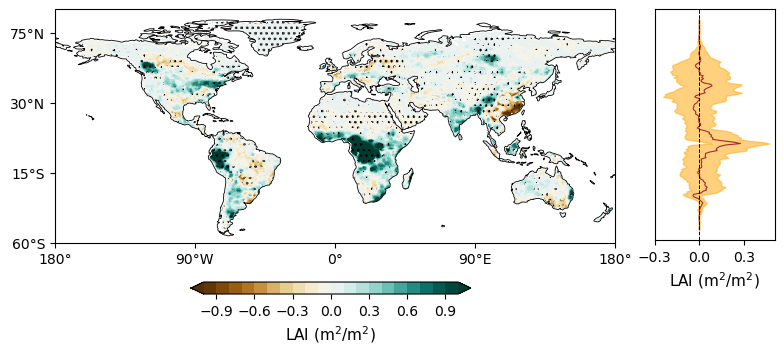

In [21]:
from matplotlib import pyplot, transforms

cmap = "BrBG"
clevs=np.arange(-1,1.1,0.1)

width_inch = 8
height_inch = 6

fig = plt.figure(figsize=(width_inch, height_inch), layout='constrained')

ax1 = fig.add_axes([0.1,0.8,0.7,0.5], projection=ccrs.PlateCarree())
# ax1.set_title("a) Multimodel Mean")
data = (lai_MM_bilin)
lats = data.lat
lons = data.lon
hatch = mm_agreement
# Add the cyclic point
#data,lons=add_cyclic_point(data,coord=data['lon'])
map = ax1.contourf(lons, lats, data, clevs, transform = ccrs.PlateCarree(), cmap=cmap,extend='both')
ax1.add_feature(cfeature.NaturalEarthFeature('physical', 'ocean', '50m', edgecolor='face', facecolor="white"))
ax1.coastlines(lw = 0.6)
# When 5 out of 7 agree
sign = np.ma.masked_less(hatch, 0.43)
map1 = ax1.pcolor(lons, lats, sign, hatch = '...', transform = ccrs.PlateCarree(), alpha=0)

# Longitude labels
ax1.set_xticks(np.arange(-180,181,90), crs=ccrs.PlateCarree()); lon_formatter = cticker.LongitudeFormatter()
ax1.xaxis.set_major_formatter(lon_formatter)
# Latitude labels
ax1.set_yticks(np.arange(-60,91,45), crs=ccrs.PlateCarree()); lat_formatter = cticker.LatitudeFormatter()
ax1.yaxis.set_major_formatter(lat_formatter)

cb_ax = fig.add_axes([0.27, 0.77, 0.35, 0.02])
cbar = plt.colorbar(map, cax=cb_ax, extend='both', orientation='horizontal', fraction=0.046, pad=0.04)  
cbar.ax.set_xlabel("LAI (m$^2$/m$^2$)", fontsize=11)

ax2 = fig.add_axes([0.85,0.86,0.15,0.385])
# ax2.set_title("b) Zonal Mean")
ax2.plot(zonal_mm.data, zonal_mm.lat, lw = 0.8, color = "brown")
ax2.fill_betweenx(zonal_mm.lat, zonal_mm.data + zonal_std.data, zonal_mm.data - zonal_std.data, alpha = 0.5, color='orange')
ax2.axvline(x = 0, linestyle = "--", linewidth = 0.7, color = "black")
ax2.set_yticks([])
ax2.set_xticks([-0.3, 0, 0.3])
ax2.set_xlabel("LAI (m$^2$/m$^2$)", fontsize=11)

title = "LAI_MM_zonal_hatch"
output_file = os.path.join(out_path, title) + ".png"
#plt.savefig(output_file, bbox_inches='tight', dpi = 500)

plt.show()
plt.close()

/var/folders/h1/tgvjn96s32q5lfh32xvkh1hh0000gp/T/ipykernel_74942/3172336496.py:50: UserWarning: There are no gridspecs with layoutgrids. Possibly did not call parent GridSpec with the "figure" keyword
  plt.savefig(output_file, bbox_inches='tight', dpi = 500)
/Users/matteomastropierro/miniconda/envs/geo_clim_py3.12/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/matteomastropierro/miniconda/envs/geo_clim_py3.12/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/var/folders/h1/tgvjn96s32q5lfh32xvkh1hh0000gp/T/ipykernel_74942/3172336496.py:50: UserWarning: There are no gridspecs with layoutgrids. Possibly did not call parent GridSpec with the "figure" keyword
  plt.savefig(output_file, bbox_inches=

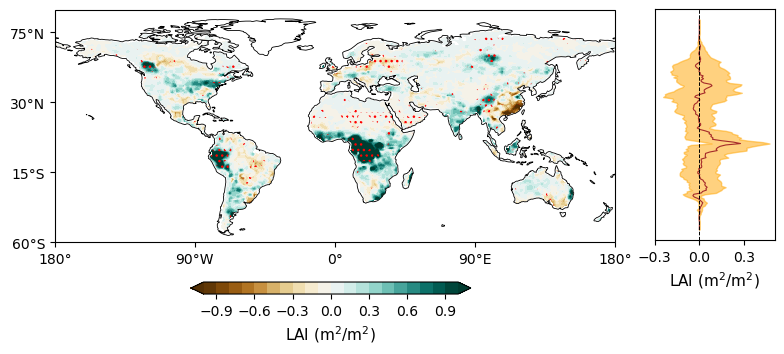

In [42]:
from matplotlib import pyplot, transforms

cmap = "BrBG"
clevs=np.arange(-1,1.1,0.1)

width_inch = 8
height_inch = 6

fig = plt.figure(figsize=(width_inch, height_inch), layout='constrained')

ax1 = fig.add_axes([0.1,0.8,0.7,0.5], projection=ccrs.PlateCarree())
# ax1.set_title("a) Multimodel Mean")
data = (lai_MM_bilin.where(aff_regr >= 0))
lats = data.lat
lons = data.lon
hatch = mm_agreement.where(aff_regr >= 0)
# Add the cyclic point
#data,lons=add_cyclic_point(data,coord=data['lon'])
map = ax1.contourf(lons, lats, data, clevs, transform = ccrs.PlateCarree(), cmap=cmap,extend='both')
ax1.add_feature(cfeature.NaturalEarthFeature('physical', 'ocean', '50m', edgecolor='face', facecolor="white"))
ax1.coastlines(lw = 0.6)
# When 5 out of 7 agree
sign = np.ma.masked_less(hatch, 0.43)
plt.rcParams['hatch.color'] = 'red'
ax1.contourf(lons, lats, sign, levels=[0.43, 1], hatches=['...'], alpha=0)
plt.rcParams['hatch.color'] = 'black'

# Longitude labels
ax1.set_xticks(np.arange(-180,181,90), crs=ccrs.PlateCarree()); lon_formatter = cticker.LongitudeFormatter()
ax1.xaxis.set_major_formatter(lon_formatter)
# Latitude labels
ax1.set_yticks(np.arange(-60,91,45), crs=ccrs.PlateCarree()); lat_formatter = cticker.LatitudeFormatter()
ax1.yaxis.set_major_formatter(lat_formatter)

cb_ax = fig.add_axes([0.27, 0.77, 0.35, 0.02])
cbar = plt.colorbar(map, cax=cb_ax, extend='both', orientation='horizontal', fraction=0.046, pad=0.04)  
cbar.ax.set_xlabel("LAI (m$^2$/m$^2$)", fontsize=11)

ax2 = fig.add_axes([0.85,0.86,0.15,0.385])
# ax2.set_title("b) Zonal Mean")
ax2.plot(zonal_mm.data, zonal_mm.lat, lw = 0.8, color = "brown")
ax2.fill_betweenx(zonal_mm.lat, zonal_mm.data + zonal_std.data, zonal_mm.data - zonal_std.data, alpha = 0.5, color='orange')
ax2.axvline(x = 0, linestyle = "--", linewidth = 0.7, color = "black")
ax2.set_yticks([])
ax2.set_xticks([-0.3, 0, 0.3])
ax2.set_xlabel("LAI (m$^2$/m$^2$)", fontsize=11)

title = "LAI_MM_zonal_hatch"
output_file = os.path.join(out_path, title) + "_red.png"
plt.savefig(output_file, bbox_inches='tight', dpi = 500)

plt.show()
plt.close()


/Users/matteomastropierro/miniconda/envs/geo_clim_py3.12/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/matteomastropierro/miniconda/envs/geo_clim_py3.12/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/matteomastropierro/miniconda/envs/geo_clim_py3.12/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/matteomastropierro/miniconda/envs/geo_clim_py3.12/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)


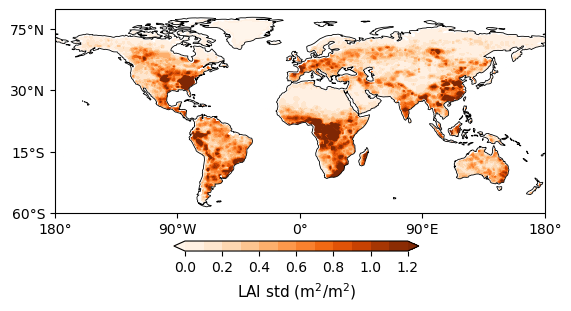

In [29]:
from matplotlib import pyplot, transforms

cmap = "Oranges"
clevs=np.arange(0,1.3,0.1)

width_inch = 7
height_inch = 5

fig = plt.figure(figsize=(width_inch, height_inch), layout='constrained')

ax1 = fig.add_axes([0.1,0.8,0.7,0.5], projection=ccrs.PlateCarree())
# ax1.set_title("a) Multimodel Mean")
data = (lai_STD_bilin)
lats = data.lat
hatch = mm_agreement
# Add the cyclic point
data,lons=add_cyclic_point(data,coord=data['lon'])
map = ax1.contourf(lons, lats, data, clevs, transform = ccrs.PlateCarree(), cmap=cmap,extend='both')
ax1.add_feature(cfeature.NaturalEarthFeature('physical', 'ocean', '50m', edgecolor='face', facecolor="white"))
ax1.coastlines(lw = 0.6)
# When 5 out of 7 agree
sign = np.ma.masked_less(hatch, 0.43)
#map1 = ax1.pcolor(lons, lats, sign, hatch = '...', transform = ccrs.PlateCarree(), alpha=0)

# Longitude labels
ax1.set_xticks(np.arange(-180,181,90), crs=ccrs.PlateCarree()); lon_formatter = cticker.LongitudeFormatter()
ax1.xaxis.set_major_formatter(lon_formatter)
# Latitude labels
ax1.set_yticks(np.arange(-60,91,45), crs=ccrs.PlateCarree()); lat_formatter = cticker.LatitudeFormatter()
ax1.yaxis.set_major_formatter(lat_formatter)

cb_ax = fig.add_axes([0.27, 0.77, 0.35, 0.02])
cbar = plt.colorbar(map, cax=cb_ax, extend='both', orientation='horizontal', fraction=0.046, pad=0.04)  
cbar.ax.set_xlabel("LAI std (m$^2$/m$^2$)", fontsize=11)

#ax2 = fig.add_axes([0.85,0.86,0.15,0.385])
# ax2.set_title("b) Zonal Mean")
#ax2.plot(zonal_std.data, zonal_std.lat, lw = 0.8, color = "brown")
#ax2.fill_betweenx(zonal_std.lat, zonal_std.data + zonal_std.data, zonal_mm.data - zonal_std.data, alpha = 0.5, color='orange')
#ax2.axvline(x = 0, linestyle = "--", linewidth = 0.7, color = "black")
#ax2.set_yticks([])
#ax2.set_xticks([-0.3, 0, 0.3])
#ax2.set_xlabel("LAI (m$^2$/m$^2$)", fontsize=11)

title = "LAI_STD_zonal"
output_file = os.path.join(out_path, title) + ".png"
plt.savefig(output_file, bbox_inches='tight', dpi = 500)

plt.show()
plt.close()

## LUH2 difference and LAI zonal and meridional average of model 

/Users/matteomastropierro/miniconda/envs/geo_clim_py3.12/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/matteomastropierro/miniconda/envs/geo_clim_py3.12/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/matteomastropierro/miniconda/envs/geo_clim_py3.12/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/matteomastropierro/miniconda/envs/geo_clim_py3.12/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)


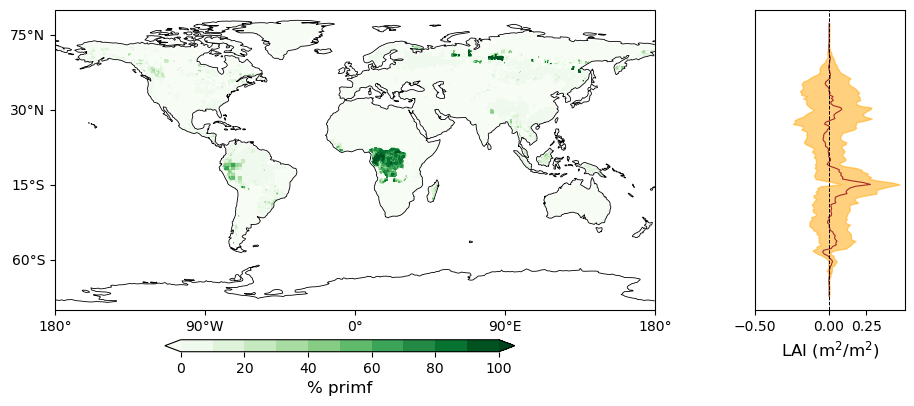

In [37]:
from matplotlib import pyplot, transforms

clevs=np.arange(0,101,10)
cmap = "Greens"

width_inch = 10
height_inch = 6

fig = plt.figure(figsize=(width_inch, height_inch), layout='constrained')

ax1 = fig.add_axes([0.1,0.8,0.7,0.5], projection=ccrs.PlateCarree())
data = (luh2_ssp126_states.primf.isel(time = -1)*100 - luh2_ssp370_states.primf.isel(time = -1)*100)
lats = data.lat
hatch = mm_agreement
data,lons=add_cyclic_point(data,coord=data['lon'])
map = ax1.contourf(lons, lats, data, clevs, transform = ccrs.PlateCarree(), cmap=cmap,extend='both')
ax1.add_feature(cfeature.NaturalEarthFeature('physical', 'ocean', '50m', edgecolor='face', facecolor="white"))
ax1.coastlines(lw = 0.6)
# When 5 out of 7 agree
sign = np.ma.masked_greater(hatch, 0.43)
#map1 = ax1.pcolor(lons, lats, sign, hatch = '///', transform = ccrs.PlateCarree(), alpha=0)

ax1.set_xticks(np.arange(-180,181,90), crs=ccrs.PlateCarree()); lon_formatter = cticker.LongitudeFormatter()
ax1.xaxis.set_major_formatter(lon_formatter)
ax1.set_yticks(np.arange(-60,91,45), crs=ccrs.PlateCarree()); lat_formatter = cticker.LatitudeFormatter()
ax1.yaxis.set_major_formatter(lat_formatter)

cb_ax = fig.add_axes([0.26, 0.73, 0.35, 0.02])
cbar = plt.colorbar(map, cax=cb_ax, extend='both', orientation='horizontal', fraction=0.046, pad=0.04)  
cbar.ax.set_xlabel("% primf", fontsize=12)


ax2 = fig.add_axes([0.85,0.8,0.15,0.5])
# ax2.set_title("b) Zonal Mean")
ax2.plot(zonal_mm.data, zonal_mm.lat, lw = 0.8, color = "brown")
ax2.fill_betweenx(zonal_mm.lat, zonal_mm.data + zonal_std.data, zonal_mm.data - zonal_std.data, alpha = 0.5, color='orange')
ax2.axvline(x = 0, linestyle = "--", linewidth = 0.7, color = "black")
ax2.set_yticks([])
ax2.set_xticks([-0.5, 0, 0.25])
ax2.set_xlabel("LAI (m$^2$/m$^2$)", fontsize=12)

title = "LUH2_MM_zonal"
output_file = os.path.join(out_path, title) + ".png"
plt.savefig(output_file, bbox_inches='tight', dpi = 500)

plt.show()
plt.close()